# Julia notebook to compute the symbolic solution to the dissipative buoyancy equation
twnh 

Dec '25   Write `ExampleSolution_v0.5.ipynb` <br>
Jun '26.  Write `BuoyancyEquationSolution.ipynb`

This notebook solves the non-dimensional, linear, time-independent buoyany equation with relaxation:
\begin{align}
Ek \frac{d}{dz} \left( \kappa \frac{d b}{d z} \right) + \Gamma ( B - b ) = 0
\end{align}
for $b(z)$, given diffusivity $\kappa = \kappa (z)$ (customized so $\kappa = 1$ at the moment), and boundary conditions
\begin{align}
\text{Surface~}z = 0: b &= b_s ,\\
\text{Bottom~}z = -H: \frac{\partial b}{\partial z} &= 0
\end{align}
where $B(z)$ is the specified relaxation buoyancy field, $b_s$ is the specified surface buoyancy field, and $\Gamma$ is the relaxation rate.

In [1]:
using SymPy

### Define symbols:

In [2]:
# Geometry symbolic parameters:
z, ξ   = symbols("z ξ",   real=true, negative=true) # Vertical coordinate and source location (both in [-H,0])
x, y   = symbols("x y",   real=true)                # Horizontal coordinates
H      = SymFunction("H", real=true, positive=true) # Domain depth H(x,y)
geometry_params = (H(x,y), z, ξ)

Ek     = symbols("Ek ",   real=true, positive=true) # Ekman number

# Buoyancy equation symbolic parameters:
b      = SymFunction("b", real=true)                # Buoyancy field b(x,y,z)
ψ      = symbols("ψ",     real=true, positive=true) # Diffusivity parameters
Γ, α   = symbols("Γ α",   real=true, positive=true) # Relaxation parameter
B      = SymFunction("B", real=true)                # Relaxation buoyancy field
bs     = SymFunction("bs",real=true)                # Surface buoyancy field bs(x,y)

# Define diffusivity profile here:
# κ = 1.0e-2 + exp(-(z + H(x,y))/0.1) ;               # PC26 Eqn (17). See `Notes on buoyancy exponential kappa profile.tex` for solution. Not yet implemented.`
κ = 1.0 + 0.0 * z                                   # Constant viscosity profile. Aspire to depth-varying profile in future.

# Define dictionaries for substitutions:
b_params = (κ, Ek , Γ) ;

#### Function to solve the buoyancy equation using a Green's function. This is where `SymPy` is unavoidable as there's no `Symbolics` equivalent to `dsolve` as of July 2026.

In [3]:
function compute_Gb(b_params, geometry_params)
    # Setup symbols and parameters:
    κexpr, Ek , Γ = b_params
    H, z, ξ = geometry_params
    b       = SymFunction("b")
    A       = symbols("A", real=true)                                   # Unknown coefficient in the Green's function solution
    
    # 0. Define the ODE for b(z):
    ode = Eq( (Ek / Γ) * diff(κexpr *  diff(b(z),z),z) - b(z), 0)

    # 1. Solve for $G_- (z)$ on $-H \le z \le ξ$:
    bm = dsolve(ode, b(z), ics = Dict(diff(b(z),z).subs(z,-H)=>0)).rhs
    @assert sympy.simplify(ode.lhs.subs(b(z),bm)) == 0                  # Check solution
    @assert sympy.simplify(diff(bm,z).subs(z,-H) - 0) == 0              # Check Neumann BC at bottom
    bm_const = filter(x -> startswith(string(x), "C"), bm.free_symbols)
    bm = bm.subs(first(bm_const), A)                                    # Replace constant with A so it doesn't conflict later

    # 2. Solve for $G_+(z)$ on  $ξ \le z \le 0$:
    bp = dsolve(ode, b(z), ics = Dict(b(0)=>0) ).rhs
    @assert sympy.simplify(ode.lhs.subs(b(z),bp)) == 0                  # Check solution
    @assert sympy.simplify(bp.subs(z,0)) == 0                           # Check Dirichlet BC at top

    # 3. Compute Wronskian $W(z)$:
    W = sympy.simplify(bm * diff(bp, z) - bp * diff(bm, z))

    # 4. Compute Green's function $G(z; ξ)$:
    Gm = sympy.simplify(bm * bp.subs(z,ξ) / (Ek * κexpr.subs(z,ξ) * W.subs(z,ξ)))
    Gp = sympy.simplify(bm.subs(z,ξ) * bp / (Ek * κexpr.subs(z,ξ) * W.subs(z,ξ)))

    # Check continuity and jump condition:
    @assert Gm.subs(z,ξ) - Gp.subs(z,ξ) == 0
    @assert sympy.simplify(diff(Gm, z).subs(z,ξ) - diff(Gp, z).subs(z,ξ)) + 1/(Ek * κexpr.subs(z,ξ)) == 0

    # Define piecewise Green's function:
    G = sympy.simplify(sympy.Piecewise((Gm, Le(z,ξ)), (Gp, Ge(z,ξ))))

    # Check boundary conditions are satisfied
    @assert sympy.simplify(diff(G,z).subs(z,-H).subs(ξ,-H//3).subs(H,1//2)) == 0
    @assert sympy.simplify(G.subs(z,0).subs(ξ,-H//3)) == 0

    return G
end

compute_Gb (generic function with 1 method)

### Compute the buoyancy Green's function:

In [4]:
Gb_sym  = compute_Gb(b_params,geometry_params)
Gb = Gb_sym.subs(Γ,ψ^2 * Ek)
println("1.1 Symbolic computation of Gb completed.")
display(Gb)

1.1 Symbolic computation of Gb completed.


⎧    ⎛     -2⋅ξ⋅ψ⎞ ⎛ 2⋅ψ⋅H(x, y)    -2⋅z⋅ψ⎞  ψ⋅(z + ξ)           
⎪0.5⋅⎝1 - ℯ      ⎠⋅⎝ℯ            + ℯ      ⎠⋅ℯ                    
⎪─────────────────────────────────────────────────────  for z ≤ ξ
⎪                    ⎛ 2⋅ψ⋅H(x, y)    ⎞                          
⎪               Ek⋅ψ⋅⎝ℯ            + 1⎠                          
⎨                                                                
⎪    ⎛     -2⋅z⋅ψ⎞ ⎛ 2⋅ψ⋅H(x, y)    -2⋅ξ⋅ψ⎞  ψ⋅(z + ξ)           
⎪0.5⋅⎝1 - ℯ      ⎠⋅⎝ℯ            + ℯ      ⎠⋅ℯ                    
⎪─────────────────────────────────────────────────────  for z ≥ ξ
⎪                    ⎛ 2⋅ψ⋅H(x, y)    ⎞                          
⎩               Ek⋅ψ⋅⎝ℯ            + 1⎠                          

In [5]:
# Compute $\partial_\xi G_b | \xi=0$ for Latex notes:
∂ξ_Gb = diff(Gb, ξ)
∂ξ_Gb_0 = ∂ξ_Gb.subs(ξ,0)
println("1.2 LaTeX vertical derivative wrt ξ of Gb at ξ=0:")
display(∂ξ_Gb_0)

    ⎛ 2⋅ψ⋅H(x, y)    -2⋅z⋅ψ⎞  z⋅ψ
1.0⋅⎝ℯ            + ℯ      ⎠⋅ℯ   
─────────────────────────────────
         ⎛ 2⋅ψ⋅H(x, y)    ⎞      
      Ek⋅⎝ℯ            + 1⎠      

1.2 LaTeX vertical derivative wrt ξ of Gb at ξ=0:


In [6]:
# Compute $z$ integral of Gb for Latex notes:
max_obj = sympy.Max(z, -H(x, y))
Gb_int = SymPy.integrate(Gb,(z,z,0))
Gb_int = Gb_int.subs(max_obj, z)
Gb_int = sympy.simplify(Gb_int)
Latex_Gb_int_den = 2 * ψ^2 * Ek * (exp(2 * ψ * H(x,y)) + 1)
Latex_Gb_int_num = 
    exp(   ψ * ( z - ξ + 2 * H(x,y))) -
    exp(   ψ * ( z + ξ + 2 * H(x,y))) +
2 * exp(   ψ * ( ξ + 2 * H(x,y) ) ) + 
2 * exp( - ψ * ξ) +  
    exp(   ψ * ( ξ - z )) - 
    exp( - ψ * ( z + ξ )) -
    exp(   ψ * ( ξ + 2 * H(x,y) -  sympy.Max( z, ξ ))) - 
    exp( - ψ * ( ξ - 2 * H(x,y) -  sympy.Max( z, ξ ) )) -
    exp(   ψ * ( ξ - sympy.Max( z, ξ ) )) - 
    exp( - ψ * ( ξ - sympy.Max( z, ξ ) )) 

@assert sympy.simplify(Latex_Gb_int_num / Latex_Gb_int_den - Gb_int) == 0
println("1.3 LaTeX Gb integral matches.")
display(Gb_int)

1.3 LaTeX Gb integral matches.


⎛       ψ⋅(z + 2⋅ξ)        ψ⋅(z + Max(z, ξ))        ψ⋅(z + 2⋅Max(z, ξ))        ↪
⎝- 0.5⋅ℯ            + 1.0⋅ℯ                  - 0.5⋅ℯ                    + 0.5⋅ ↪
────────────────────────────────────────────────────────────────────────────── ↪
                                                                               ↪
                                                                               ↪

↪  ψ⋅(2⋅ξ + Max(z, ξ))        ψ⋅(z + 2⋅ξ + 2⋅H(x, y))        ψ⋅(z + 2⋅H(x, y)  ↪
↪ ℯ                    - 0.5⋅ℯ                        - 0.5⋅ℯ                  ↪
↪ ──────────────────────────────────────────────────────────────────────────── ↪
↪                                                                              ↪
↪                                                                              ↪

↪ + 2⋅Max(z, ξ))        ψ⋅(2⋅z + 2⋅H(x, y) + Max(z, ξ))        ψ⋅(z + 2⋅ξ + 2⋅ ↪
↪                + 0.5⋅ℯ                                + 1.0⋅ℯ                ↪
↪ ────────────────────────

### Make plots

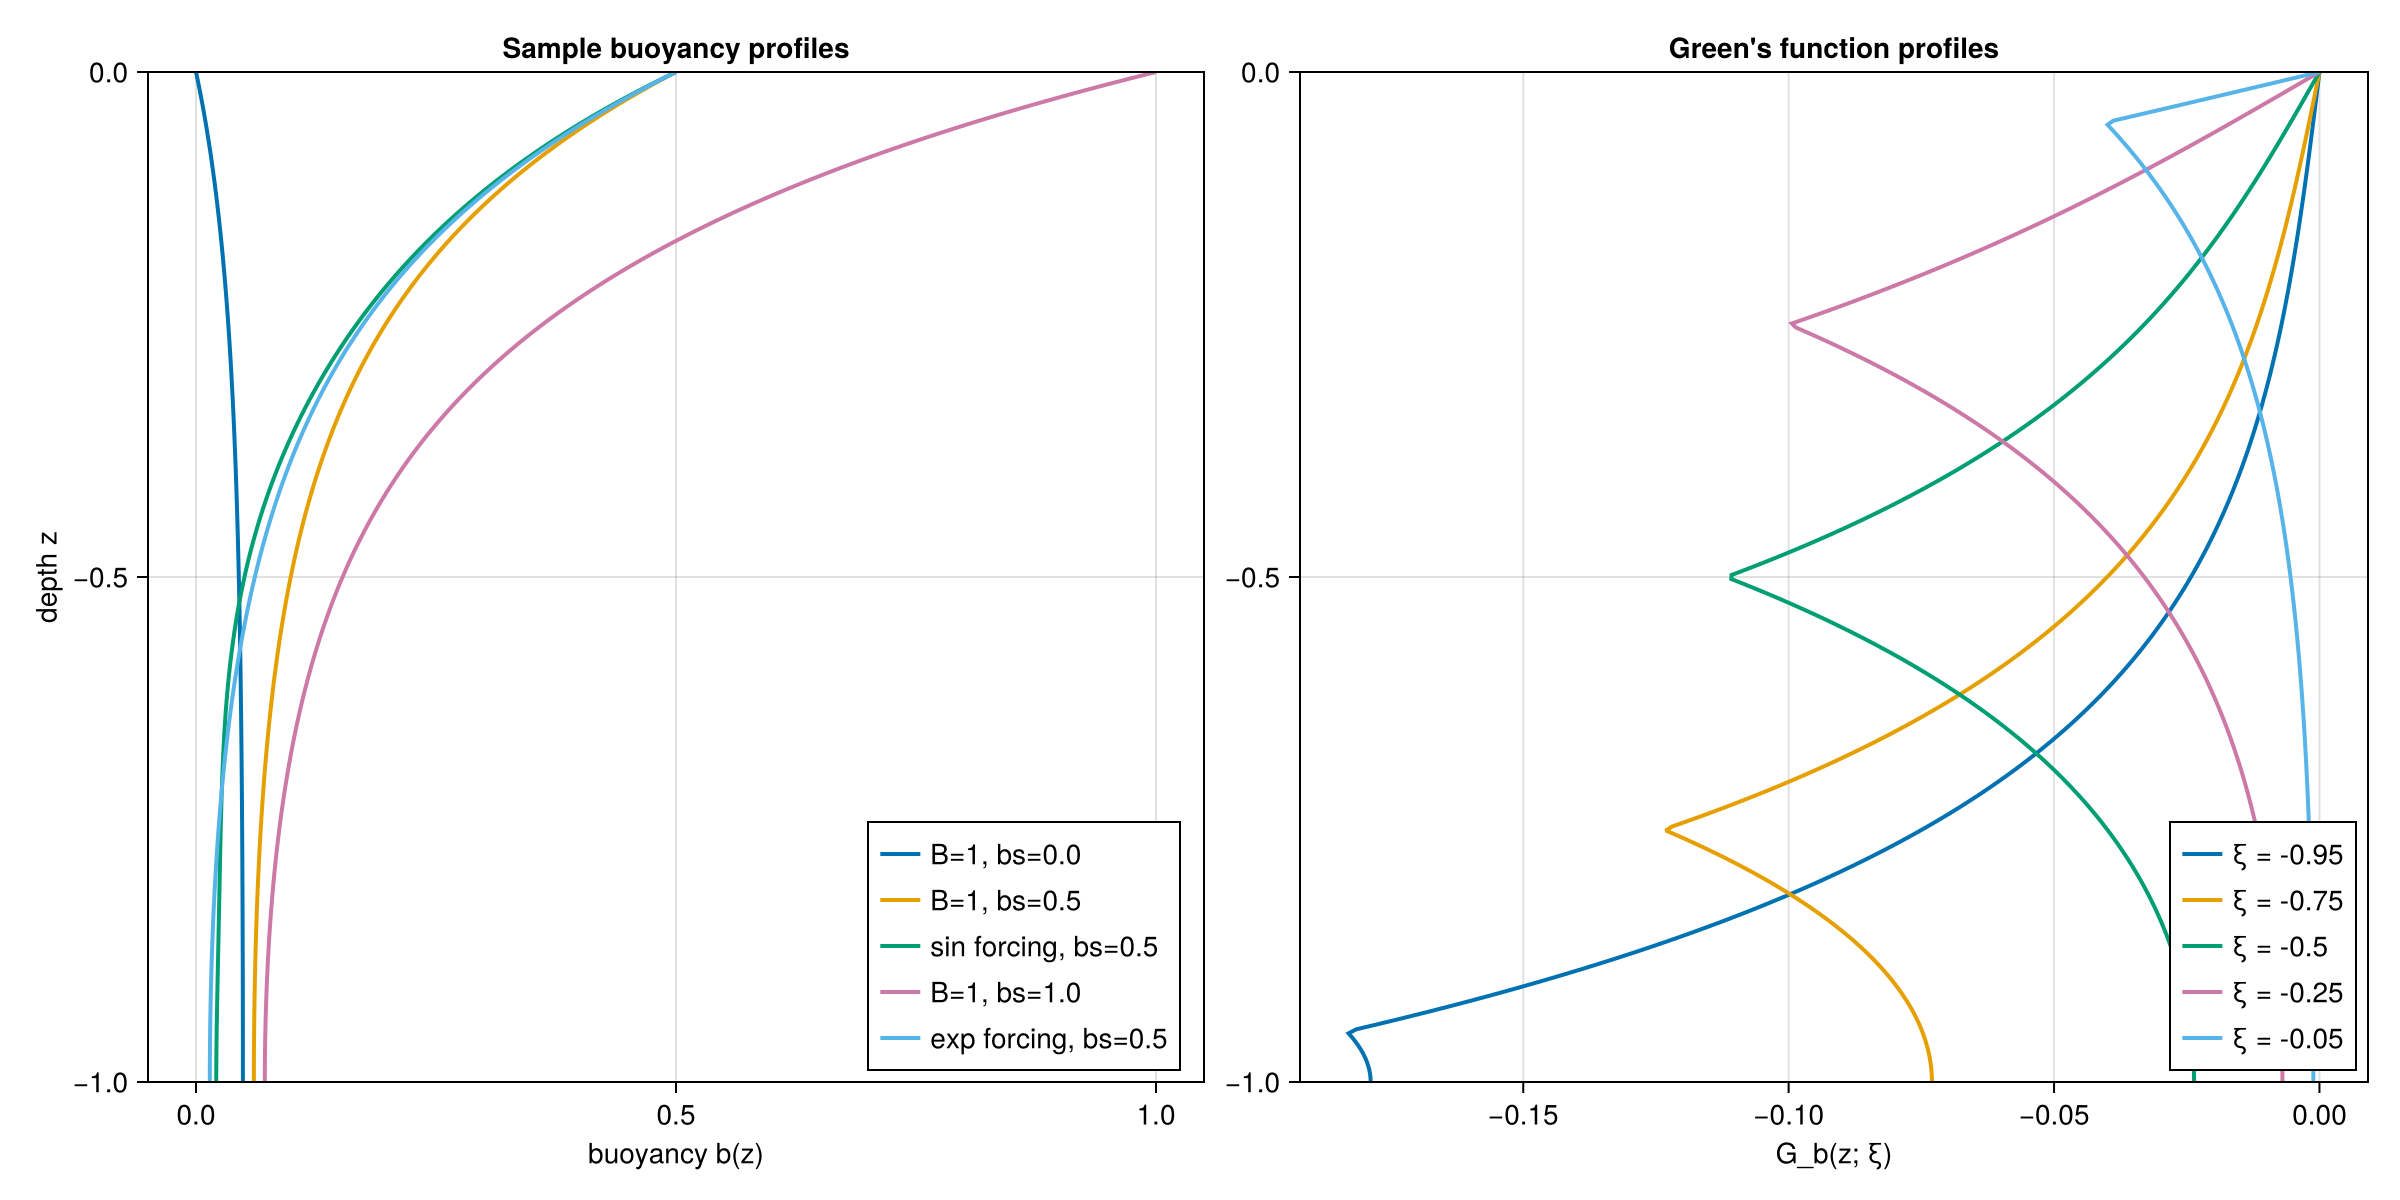

In [18]:
using CairoMakie
using QuadGK

# -----------------------------
# Parameters
# -----------------------------
H   = 1.0        # depth
Γ   = 1.0        # relaxation coefficient
Ek  = 0.05       # Ekman number
ψ   = sqrt(Γ / Ek)

# Grid
zgrid  = range(-H, 0.0, length=250)

# -----------------------------
# Green's function G_b(z; ξ)
# Piecewise definition from the paper
# -----------------------------
function G_b(z, ξ; H=1.0, ψ=1.0)
    pref = exp(ψ * (z + ξ)) / (2ψ * (exp(2ψ*H) + 1))

    if z <= ξ
        return pref * (1 - exp(-2ψ*ξ)) * (exp(2ψ*H) + exp(-2ψ*z))
    else
        return pref * (1 - exp(-2ψ*z)) * (exp(2ψ*H) + exp(-2ψ*ξ))
    end
end

# -----------------------------
# Analytic ∂_ξ G_b(z; 0)
# -----------------------------
function dGdξ_at0(z; H=1.0, ψ=1.0, Ek=1.0)
    return exp(ψ*z) * (exp(2ψ*H) + exp(-2ψ*z)) / (Ek * (exp(2ψ*H) + 1))
end

# -----------------------------
# Buoyancy profile b(z)
# -----------------------------
function b_profile(z; H=1.0, Γ=1.0, Ek=0.05, ψ=sqrt(1/0.05), bs=0.0, Bfunc=ξ->0.0)
    integrand(ξ) = G_b(z, ξ; H=H, ψ=ψ) * Bfunc(ξ)
    I, _ = quadgk(integrand, -H, 0.0)
    surf = Ek * dGdξ_at0(z; H=H, ψ=ψ, Ek=Ek) * bs
    return -Γ * I + surf
end

# -----------------------------
# Example forcing profiles B(ξ)
# -----------------------------
B1(ξ) = 1.0
B2(ξ) = exp(4ξ / H)
B3(ξ) = 0.5 * sin(3π * (ξ + H) / H)

# -----------------------------
# Compute buoyancy profiles
# -----------------------------
bs_vals = [0.0, 0.5, 1.0]

profiles = Dict{String, Vector{Float64}}()

for bs in bs_vals
    profiles["B=1, bs=$(bs)"] = [b_profile(z; H=H, Γ=Γ, Ek=Ek, ψ=ψ, bs=bs, Bfunc=B1) for z in zgrid]
end

bs_fixed = 0.5
profiles["exp forcing, bs=$(bs_fixed)"] = [b_profile(z; H=H, Γ=Γ, Ek=Ek, ψ=ψ, bs=bs_fixed, Bfunc=B2) for z in zgrid]
profiles["sin forcing, bs=$(bs_fixed)"] = [b_profile(z; H=H, Γ=Γ, Ek=Ek, ψ=ψ, bs=bs_fixed, Bfunc=B3) for z in zgrid]

# -----------------------------
# Figure: side-by-side plots with shared y-axis
# -----------------------------
fig = Figure(size=(1200, 600))

# Left panel: buoyancy profiles
ax1 = Axis(fig[1, 1],
    xlabel = "buoyancy b(z)",
    ylabel = "depth z",
    title  = "Sample buoyancy profiles"
)

for (label, vals) in profiles
    lines!(ax1, vals, zgrid, label=label, linewidth=2)
end
axislegend(ax1, position=:rb)

# Right panel: Green's function profiles for fixed ξ
ξvals = [-0.95H, -0.75H, -0.5H, -0.25H, -0.05H]

ax2 = Axis(fig[1, 2],
    xlabel = "G_b(z; ξ)",
    title  = "Green's function profiles"
)

for ξ in ξvals
    Gvals = [G_b(z, ξ; H=H, ψ=ψ) for z in zgrid]
    lines!(ax2, Gvals, zgrid, linewidth=2, label="ξ = $(round(ξ, digits=2))")
end
axislegend(ax2, position=:rb)

# Share y-axis between panels
linkyaxes!(ax1, ax2)

# Make depth range consistent
ylims!(ax1, -H, 0.0)

fig

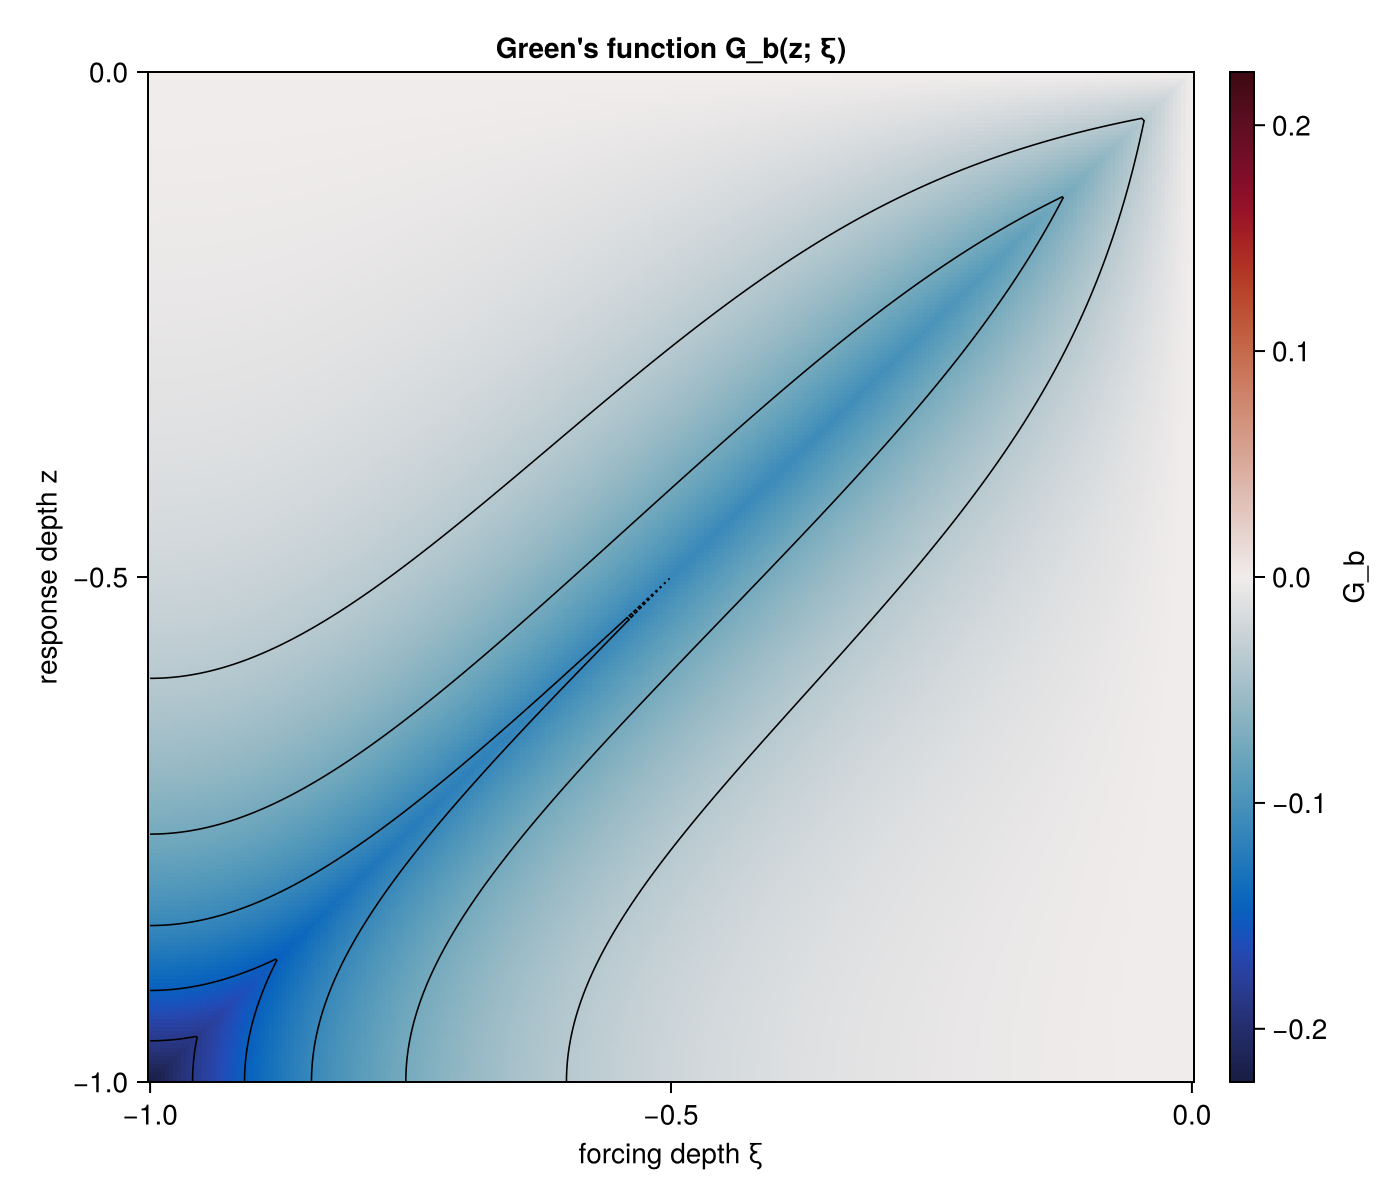

In [17]:
fig3 = Figure(size=(700, 600))

ax3 = Axis(fig3[1, 1],
    xlabel = "forcing depth ξ",
    ylabel = "response depth z",
    title = "Green's function G_b(z; ξ)"
)

clim = maximum(abs, Gmat)
hm = heatmap!(ax3, xigrid, zgrid, Gmat,
    colormap = :balance,
    colorrange = (-clim, clim)
)

contour!(ax3, xigrid, zgrid, Gmat, color=:black, linewidth=0.8)

Colorbar(fig3[1, 2], hm, label="G_b")

ylims!(ax3, -H, 0.0)

fig3